In [1]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt

In [2]:
file = "gebco_2026_n38.4_s37.2_w-26.3_e-24.6_geotiff.tif"

In [3]:
# Open file
with rasterio.open(file) as src:

    elevation = src.read(1, masked=True)

    # Bounds 
    bounds = src.bounds

    # Dimensions
    rows = src.height
    cols = src.width

    # Pixel size
    resolution = src.res

    # Crs
    crs = src.crs

    # Pixels to map coords
    transform = src.transform

In [4]:
# Map extent
extent = [bounds.left, bounds.right, bounds.bottom, bounds.top]

In [5]:
# Data type to float, mask invalid numbers
data = np.ma.masked_invalid(np.ma.asarray(elevation, dtype=float))

In [6]:
# Contour levels
minor_interval = 10       
major_interval = 500      
minimum_depth = -5000     
maximum_depth = -50       

minor_linewidth = 0.25
major_linewidth = 0.65

In [7]:
# Minor levels 
minor_levels = np.arange(minimum_depth, maximum_depth + minor_interval, minor_interval)

# Major levels 
major_levels = np.arange(minimum_depth, maximum_depth + major_interval, major_interval)

In [8]:
# Array of unmasked, valid values
valid_values = data.compressed()

In [9]:
# Min, max values
data_min = valid_values.min()
data_max = valid_values.max()

In [10]:
# Contour levels between min, max values
minor_levels = minor_levels[(minor_levels >= data_min) & (minor_levels <= data_max)]
major_levels = major_levels[(major_levels >= data_min) &(major_levels <= data_max)]

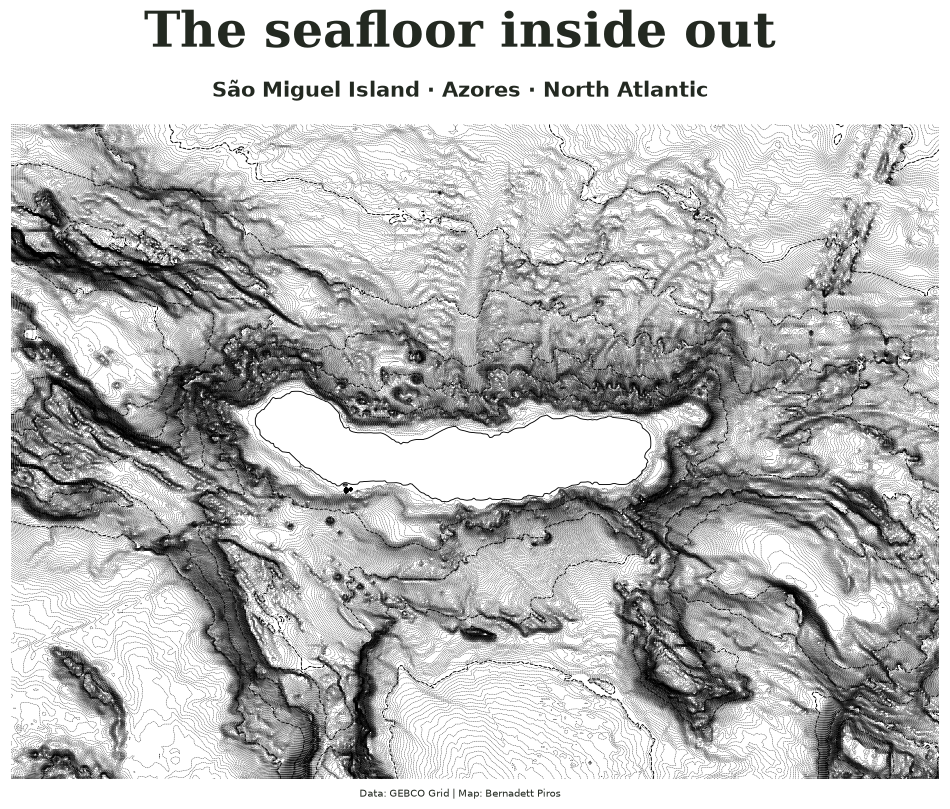

In [11]:
fig, ax = plt.subplots(figsize=(12, 10))

# Minor contours
minor_contours = ax.contour(data, levels=minor_levels, colors="black", linewidths=minor_linewidth,
                            origin="upper", extent=extent, antialiased=True, corner_mask=True)

# Major contours
major_contours = ax.contour(data, levels=major_levels, colors="black", linewidths=major_linewidth,
                            origin="upper", extent=extent, antialiased=True, corner_mask=True)

# Axis limits
ax.set_xlim(bounds.left, bounds.right)
ax.set_ylim(bounds.bottom, bounds.top)

# Aspect ratio
ax.set_aspect("equal")

# Hide axis
ax.axis("off")

# Title
fig.text(0.5, 0.9,
    "The seafloor inside out",
    #"São Miguel Island, Azores",
   color="#232921", size=35, weight="bold", fontfamily="serif", ha="center")

# subitle
fig.text(0.5, 0.85,
    "São Miguel Island · Azores · North Atlantic",
    #"São Miguel Island, Azores",
   color="#232921", size=15, weight="bold", ha="center")

# Caption
fig.text(0.5, 0.15,
         "Data: GEBCO Grid | Map: Bernadett Piros",
         color="#232921", size=7, ha="center")

plt.show()

# Save figure
#fig.savefig("inside_out.png", bbox_inches="tight", pad_inches=0.2) 